# Módulo 2 (continuação) — Análise estatística comparativa: NFStream+rotulagem vs. CICIDS2017 original
**Objetivo:** comparar, com análises descritivas e de frequência, a base de fluxos gerada por nós (PCAP → NFStream → rotulagem por IP/tempo) com a base original da CICIDS2017 (PCAP → CICFlowMeter, já rotulada pelos autores), para o dia de quinta-feira (06/07/2017).
**Autor:** Marcel Teixeira Chiarelo
**Data:** julho/2026


In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from rotulagem_cicids2017 import ler_csv_original_cicids2017, normalizar_label

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (9, 4)


## 1. Carregar as duas bases

- **Base A (nossa):** saída da notebook `modulo2_rotulagem.ipynb` — fluxos do NFStream (dia inteiro de quinta) com a coluna `Label` reconstruída por IP + tempo.
- **Base B (original):** os dois CSVs oficiais da CICIDS2017 de quinta-feira (`Morning-WebAttacks` + `Afternoon-Infilteration`), concatenados para cobrir o dia inteiro e ficar comparável com a Base A.

Atenção: o CSV original é a versão "reduzida" da CICIDS2017 — **não tem** colunas de IP, porta ou protocolo, só as features estatísticas + `Label`. Por isso algumas comparações abaixo (protocolo) só aparecem para a Base A. As colunas vêm com espaço à frente (ex. `" Label"`) e alguns rótulos usam caracteres especiais (`–` en-dash). A leitura é feita por `ler_csv_original_cicids2017()` (em `rotulagem_cicids2017.py`), que testa os encodings em ordem (utf-8, cp1252, latin1) e já limpa os nomes de coluna.


In [2]:
CAMINHO_BASE_A = "nfstream_cicids2017_rotulado.csv"
ORIGINAL_CSVS = sorted(glob.glob("dados/Thursday-*.csv"))

base_a = pd.read_csv(CAMINHO_BASE_A)
base_b = ler_csv_original_cicids2017(ORIGINAL_CSVS)

print("Base A (NFStream + rotulagem):", base_a.shape)
print("Base B (CICIDS2017 original):", base_b.shape)
print("Rotulos unicos - Base A:", sorted(base_a["Label"].unique()))
print("Rotulos unicos - Base B:", sorted(base_b["Label"].unique()))


[ler_csv_original_cicids2017] dados/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: lido com encoding='utf-8'
[ler_csv_original_cicids2017] dados/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: lido com encoding='utf-8'
Base A (NFStream + rotulagem): (343134, 40)
Base B (CICIDS2017 original): (458968, 79)
Rotulos unicos - Base A: ['BENIGN', 'Infiltration', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']
Rotulos unicos - Base B: ['BENIGN', 'Infiltration', 'Web Attack � Brute Force', 'Web Attack � Sql Injection', 'Web Attack � XSS']


### Normalizar rótulos antes de comparar

O CSV original da CICIDS2017 já traz o traço de alguns rótulos (`Web Attack - XSS` etc.) substituído pelo caractere U+FFFD ("replacement character"), gravado como UTF-8 válido dentro do próprio arquivo. Ou seja, a informação original já estava perdida antes de chegar até mim: nenhum encoding na leitura recupera o caractere (testei utf-8, cp1252 e latin1).

Por isso normalizo os rótulos das duas bases com `normalizar_label()` (remove tudo que não é letra/número e coloca em minúsculas) só para servir de **chave de comparação**. Os rótulos originais continuam intactos para qualquer output final.


In [3]:
base_a["Label_norm"] = base_a["Label"].map(normalizar_label)
base_b["Label_norm"] = base_b["Label"].map(normalizar_label)

# Nome "bonito" para exibir: preferimos o rótulo da Base A (não está
# corrompido); só usamos o da Base B se a classe não existir na Base A.
nomes_exibicao = (
    pd.concat([base_a[["Label_norm", "Label"]], base_b[["Label_norm", "Label"]]])
    .drop_duplicates(subset="Label_norm", keep="first")
    .set_index("Label_norm")["Label"]
)
print("Classes apos normalizacao:", sorted(nomes_exibicao.values))


Classes apos normalizacao: ['BENIGN', 'Infiltration', 'Web Attack - Brute Force', 'Web Attack - Sql Injection', 'Web Attack - XSS']


## 2. Análise de frequência — distribuição de classes (Label)

Primeira comparação: como as duas bases se distribuem entre BENIGN e os diferentes tipos de ataque.


In [4]:
freq_a = base_a["Label_norm"].value_counts()
freq_b = base_b["Label_norm"].value_counts()

freq = pd.DataFrame({
    "NFStream (nosso)": freq_a,
    "% NFStream": (freq_a / freq_a.sum() * 100).round(2),
    "CICIDS2017 (original)": freq_b,
    "% original": (freq_b / freq_b.sum() * 100).round(2),
}).fillna(0)
freq["NFStream (nosso)"] = freq["NFStream (nosso)"].astype(int)
freq["CICIDS2017 (original)"] = freq["CICIDS2017 (original)"].astype(int)
freq.index = freq.index.map(nomes_exibicao)
freq.index.name = "Label"
freq


,NFStream (nosso),% NFStream,CICIDS2017 (original),% original
Label,,,,
BENIGN,285981,83.34,456752,99.52
Infiltration,55134,16.07,36,0.01
Web Attack - Brute Force,1349,0.39,1507,0.33
Web Attack - Sql Injection,9,0.00,21,0.00
Web Attack - XSS,661,0.19,652,0.14


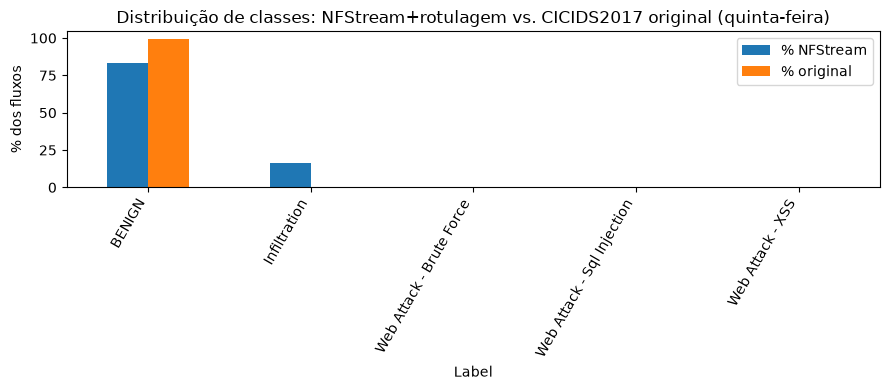

In [5]:
fig, ax = plt.subplots()
freq[["% NFStream", "% original"]].plot(kind="bar", ax=ax)
ax.set_ylabel("% dos fluxos")
ax.set_title("Distribuição de classes: NFStream+rotulagem vs. CICIDS2017 original (quinta-feira)")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


### Teste qui-quadrado de aderência

Testa se as duas distribuições de classe são estatisticamente diferentes (H0: mesma distribuição proporcional). Como as duas bases quase certamente têm número total de fluxos diferente, comparamos as **proporções** — reescalamos a base B para o total da base A antes do teste.


In [6]:
classes_comuns = freq.index
obs_a = freq.loc[classes_comuns, "NFStream (nosso)"].astype(float).values
prop_b = (freq.loc[classes_comuns, "CICIDS2017 (original)"] / freq["CICIDS2017 (original)"].sum()).values

# remove classes com proporcao esperada 0 (qui-quadrado exige esperado > 0)
mask = prop_b > 0
obs_masked = obs_a[mask]
# o esperado eh recalculado APOS o mascaramento, usando a soma dos observados
# mascarados -- se calculassemos com obs_a.sum() (antes do mascaramento) a soma
# de f_obs e f_exp poderia nao bater exatamente, o que o scipy rejeita com ValueError.
esperado_masked = prop_b[mask] * obs_masked.sum()
chi2, p = stats.chisquare(f_obs=obs_masked, f_exp=esperado_masked)
print(f"chi2 = {chi2:.2f}   p-valor = {p:.4g}")
print("Interpretação: p-valor baixo (< 0.05) indica que a distribuição de classes das duas bases difere de forma estatisticamente significativa.")


chi2 = 112840804.13   p-valor = 0
Interpretação: p-valor baixo (< 0.05) indica que a distribuição de classes das duas bases difere de forma estatisticamente significativa.


## 3. Análise descritiva geral

Comparação das estatísticas descritivas básicas de duração, pacotes e bytes por fluxo. As colunas têm nomes diferentes entre as duas ferramentas (NFStream vs. CICFlowMeter) — o dicionário abaixo faz o mapeamento das métricas equivalentes mais importantes.


In [7]:
# Mapeamento de colunas equivalentes entre NFStream e CICFlowMeter/CICIDS2017 original
MAPA_COLUNAS = {
    "Duração do fluxo (ms)": ("bidirectional_duration_ms", "Flow Duration"),
    "Pacotes (fwd)": ("src2dst_packets", "Total Fwd Packets"),
    "Pacotes (bwd)": ("dst2src_packets", "Total Backward Packets"),
    "Bytes (fwd)": ("src2dst_bytes", "Total Length of Fwd Packets"),
    "Bytes (bwd)": ("dst2src_bytes", "Total Length of Bwd Packets"),
}

linhas = []
for nome, (col_a, col_b) in MAPA_COLUNAS.items():
    desc_a = base_a[col_a].describe() if col_a in base_a.columns else None
    desc_b = base_b[col_b].describe() if col_b in base_b.columns else None
    linhas.append({
        "métrica": nome,
        "média (NFStream)": None if desc_a is None else round(desc_a["mean"], 2),
        "mediana (NFStream)": None if col_a not in base_a.columns else round(base_a[col_a].median(), 2),
        "desvio padrão (NFStream)": None if desc_a is None else round(desc_a["std"], 2),
        "média (original)": None if desc_b is None else round(desc_b["mean"], 2),
        "mediana (original)": None if col_b not in base_b.columns else round(base_b[col_b].median(), 2),
        "desvio padrão (original)": None if desc_b is None else round(desc_b["std"], 2),
    })

tabela_descritiva = pd.DataFrame(linhas)
tabela_descritiva


,métrica,média (NFStream),mediana (NFStream),desvio padrão (NFStream),média (original),mediana (original),desvio padrão (original)
0,Duração do fluxo (ms),15221.16,32.0,51931.73,10269578.09,23106.5,29296614.27
1,Pacotes (fwd),12.55,2.0,1814.93,9.53,2.0,686.82
2,Pacotes (bwd),14.46,2.0,2446.67,10.60,2.0,914.82
3,Bytes (fwd),1372.92,158.0,114534.25,562.79,58.0,21187.05
4,Bytes (bwd),21902.26,250.0,5513862.85,15690.46,106.0,2113918.98


**Nota importante para o relatório:** essa comparação é aproximada, não uma equivalência exata — o NFStream e o CICFlowMeter implementam a extração de fluxo de forma diferente (parâmetros de timeout, tratamento de flags TCP), então mesmo describindo o "mesmo" tráfego os números não batem perfeitamente. Isso deve ser discutido no texto como diferença metodológica entre ferramentas, não como erro de uma das duas — o mesmo ponto já foi levantado na Seção 4 da notebook `modulo2_nfstream_pcap_cicids2017.ipynb`.

## 4. Distribuição de protocolos

Só é possível para a Base A — o CSV original (versão reduzida) não tem coluna de protocolo.


In [8]:
PROTO_MAP = {6: "TCP", 17: "UDP", 1: "ICMP"}

proto_a = base_a["protocol"].map(PROTO_MAP).fillna(base_a["protocol"]).value_counts()
print("Distribuição de protocolos (NFStream):")
proto_a


Distribuição de protocolos (NFStream):


protocol
UDP     182743
TCP     160206
ICMP       104
58          54
2           27
Name: count, dtype: int64

## 5. Fluxos benignos vs. maliciosos — visão geral

In [9]:
def binario(label):
    return "BENIGN" if str(label).strip().upper() == "BENIGN" else "ATTACK"

bin_a = base_a["Label"].map(binario).value_counts(normalize=True) * 100
bin_b = base_b["Label"].map(binario).value_counts(normalize=True) * 100

pd.DataFrame({"% NFStream": bin_a, "% original": bin_b}).round(2)


,% NFStream,% original
Label,,
BENIGN,83.34,99.52
ATTACK,16.66,0.48


## Reflexão

- **Proporção BENIGN contra ataque:** as duas bases não concordam. Na minha rotulagem, 83,34% dos fluxos são BENIGN e 16,66% são ataque; no CSV oficial, 99,52% e 0,48%. A diferença vem quase toda da Infiltration (16,07% na minha base contra 0,01% no oficial). Sem ela, os ataques somam 2.019 fluxos em 288.000 (0,70%), contra 0,48% no oficial.

- **Classes com maior divergência:** a Infiltration (55.134 contra 36). As classes de Web Attack ficaram próximas (Brute Force 1.349 contra 1.507; XSS 661 contra 652; Sql Injection 9 contra 21). Para os Web Attack isso é esperado: janelas de horário aproximadas, um par de IP bem definido e menos fluxos no NFStream. Para a Infiltration não é: a diferença é de ordem de grandeza e provavelmente vem da janela de portscan interno, para a qual o CIC não publica um IP de vítima único. O critério amplo que adotei (`*_local`) captura muito mais tráfego do que o rótulo oficial, que cobre poucos pares de IP.

- **Teste qui-quadrado:** χ² = 112.840.804,13 e p ≈ 0, ou seja, a distribuição de classes das duas bases difere de forma estatisticamente significativa. Com centenas de milhares de fluxos o teste detecta qualquer diferença, e aqui ela é dominada pela Infiltration, então o p-valor pouco acrescenta além da leitura da tabela de frequências.

- **Estatísticas descritivas:** a coluna `Flow Duration` do CSV original está em microssegundos, e a tabela mostra o valor bruto, enquanto o NFStream está em ms. Convertendo, o fluxo médio dura 15.221 ms no NFStream e cerca de 10.270 ms no original, e as medianas são 32 ms e cerca de 23 ms. A mediana de pacotes é igual (2 em cada direção); a média no NFStream é maior (12,55 contra 9,53 pacotes fwd e 14,46 contra 10,60 bwd). Em bytes a diferença é maior (mediana fwd 158 contra 58; bwd 250 contra 106), provavelmente porque o NFStream conta o tamanho do pacote IP e o CICFlowMeter só o payload. Tudo isso é compatível com o CICFlowMeter quebrando conexões longas em mais fluxos.

- **Protocolos (NFStream):** UDP 182.743 (53,3%), TCP 160.206 (46,7%), ICMP 104, protocolo 58 (ICMPv6) 54 e protocolo 2 (IGMP) 27. O CSV original não tem coluna de protocolo, então não há comparação.

- **Qualidade da rotulagem por IP e horário:** funciona bem quando há um par de IP bem definido (Web Attack e, na análise da semana, PortScan), mas superestima classes cuja janela não tem uma vítima única, como o portscan interno da Infiltration. Ela não olha porta nem comportamento do fluxo.

- **Ajustes que poderiam reduzir a divergência:** (1) restringir o critério de vítima do portscan interno, depois de decompor a contagem de Infiltration por janela; (2) rodar o NFStream com `active_timeout` e `idle_timeout` mais próximos dos 120 s do CICFlowMeter, para reduzir a diferença de granularidade; (3) testar uma margem de um minuto nas janelas de horário.